# 02 · Chunking and Indexing

Documents are split into retrievable passages ("chunks"):
- **Internal Markdown** → one chunk per `##` section; long sections fall back to a sliding window (220 words, 40 overlap).
- **Regulations (PDF)** → split on article boundaries (`Pasal N`) and grouped into windows, keeping the page number for citations.

Each chunk is indexed with a **breadcrumb** (`doc_id title > section`) prepended, so short sections such as *"4. Fees"* still carry their context.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from src.ingest import load_corpus
from src.chunking import chunk_corpus
docs = load_corpus()
chunks = chunk_corpus(docs)
cdf = pd.DataFrame([c.to_dict() for c in chunks])
cdf["words"] = cdf["text"].str.split().str.len()
print(f"{len(docs)} documents -> {len(cdf)} chunks")
cdf[["chunk_id", "section", "words"]].head(10)

20 documents -> 84 chunks


,chunk_id,section,words
0,GUIDE-COM-01::00,1. Response Time Commitments,37
1,GUIDE-COM-01::01,2. Reporting Official Documents,19
2,GUIDE-COM-01::02,3. Language,20
3,GUIDE-COM-01::03,4. Tone and Content,34
4,GUIDE-COM-01::04,5. Escalation,19
5,GUIDE-DSP-01::00,1. Scope,15
6,GUIDE-DSP-01::01,2. Intake,31
7,GUIDE-DSP-01::02,3. Cease-and-Desist Letters,20
8,GUIDE-DSP-01::03,4. Marketplace Takedowns,30
9,GUIDE-DSP-01::04,5. Escalation to Litigation,30


In [3]:
cdf.groupby("source_type")["words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
source_type,,,,,,,,
internal,84.0,34.8,19.4,11.0,20.8,30.0,45.2,87.0


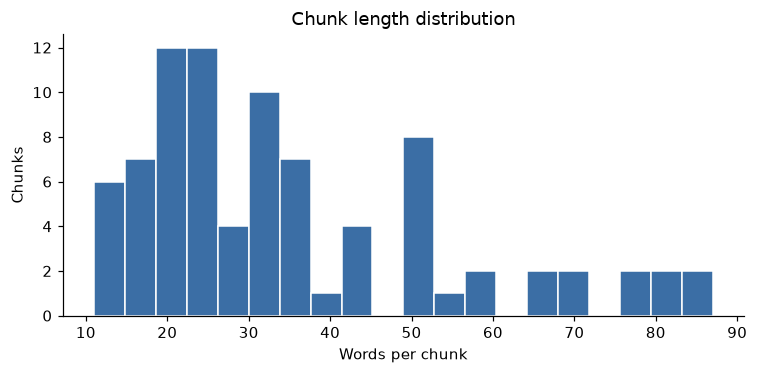

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(cdf["words"], bins=20, color="#3b6ea5", edgecolor="white")
ax.set_xlabel("Words per chunk"); ax.set_ylabel("Chunks"); ax.set_title("Chunk length distribution")
plt.tight_layout(); plt.savefig("reports/figures/02_chunk_length.png"); plt.show()

In [5]:
print(chunks[5].text_for_index)

GUIDE-DSP-01 IP Enforcement and Dispute Escalation > 1. Scope
Cease-and-desist letters, cancellation actions, online marketplace takedowns and support for litigation in the Commercial Court.


### Build the index
`python -m src.build_index` writes `data/processed/chunks.jsonl` and, when `GEMINI_API_KEY` is set, `embeddings.npy` (gemini-embedding-001, 768 dimensions, L2-normalised).
Without a key the project still works in **BM25 mode**.

In [6]:
from src import config
from src.build_index import main as build_index
build_index(embed=bool(config.GEMINI_API_KEY))

20 documents (20 internal, 0 regulations) -> 84 chunks
[embed] 20/84 texts embedded
[embed] 40/84 texts embedded
[embed] 60/84 texts embedded
[embed] 80/84 texts embedded
[embed] 84/84 texts embedded
Saved embeddings (84, 768) to data\processed\embeddings.npy
